# Phase 4 — Candidate Generation at Full Scale

**Purpose.** Run the Phase 3 retrieval (same-country name top-K1 ∪ address top-K2) against the **full** S2+S3 pool for a sample of train and
validation S1 entities, then measure the *real* recall (replacing Phase 3's extrapolation), the candidate-list quality, and the ceiling it puts on the
final score. The output is the labelled candidate table the classifier will learn from.

**Discipline.**
- Retrieval itself uses **no labels** — so val queries can be generated now without leaking anything.
- Train labels build the training table. **Val labels are used only to report recall** (a held-out check of the Phase 3 estimate); nothing is tuned on them.
- Settings come only from `retrieval_config.json` (Phase 3) — nothing is changed here.

**Scale note.** The full run builds a ~10 M-record index one country at a time (several GB of RAM) and takes roughly 40–60 min on 2 cores.
Results are cached per country, so an interrupted run resumes. Set `N_TRAIN_Q`/`N_VAL_Q` lower for a quick laptop pass.

**Sections:** 1 Scope + query sample → 2 Generate → 3 Candidate-list stats → 4 Real recall + ceiling → 5 Candidate quality → 6 Save labelled table → 7 Summary

In [1]:
import os, sys, re, json, time, pickle, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import candidate_generation as CG

ROOT = "../../../"
TRAIN_DIR = ROOT + "dataset/train"; SPLIT_DIR = ROOT + "dataset/split"; INTERIM = ROOT + "dataset/interim"
os.makedirs(INTERIM, exist_ok=True)
CFG = CG.load_cfg()
K1, K2 = CFG["K_name"], CFG["address_route"]["K_addr"]
SEED, N_TRAIN_Q, N_VAL_Q = 42, 24_000, 6_000
S2P, S3P = TRAIN_DIR + "/train_source2.tsv", TRAIN_DIR + "/train_source3.tsv"
pd.set_option("display.width", 170)
print(f"retrieval config: name K1={K1} (max_df {CFG['name_vectorizer']['max_df']}), address K2={K2} (max_df {CFG['address_route']['max_df']}), same-country only")

retrieval config: name K1=20 (max_df 0.01), address K2=20 (max_df 0.05), same-country only


## 1. Scope and query sample
Random train and val S1 entities (singletons included — they are ~5.6 % of entities and every candidate for them is a negative).

In [2]:
train_ids = open(SPLIT_DIR + "/train_s1_ids.txt").read().split()
val_ids = open(SPLIT_DIR + "/val_s1_ids.txt").read().split()
assert set(train_ids).isdisjoint(val_ids)
r = np.random.default_rng(SEED)
tr_s = set(r.choice(train_ids, N_TRAIN_Q, replace=False)); va_s = set(r.choice(val_ids, N_VAL_Q, replace=False))
s1 = pd.read_csv(TRAIN_DIR + "/train_source1.tsv", sep="\t", dtype=str, keep_default_na=False)
s1 = s1[s1["entity_id"].isin(tr_s | va_s)].rename(columns={"entity_id": "s1_id", "business_name": "s1_name", "business_address": "s1_addr"})
s1["split"] = np.where(s1["s1_id"].isin(tr_s), "train", "val")
print(s1["split"].value_counts().to_dict(), "| by country:", s1.groupby(["split", "country"]).size().to_dict())
QPATH, CPATH = INTERIM + "/phase4_queries.pkl", INTERIM + "/phase4_candidates.pkl"
pickle.dump(s1[["s1_id", "s1_name", "s1_addr", "country"]], open(QPATH, "wb"))

{'train': 24000, 'val': 6000} | by country: {('train', 'India'): 9614, ('train', 'US'): 14386, ('val', 'India'): 2438, ('val', 'US'): 3562}


## 2. Generate candidates (full pool)
Runs `candidate_generation.py` as a subprocess (so the big index memory is released when it ends). Skipped if the cached result exists.

In [3]:
if os.path.exists(CPATH):
    print("cached candidates found:", CPATH)
else:
    t0 = time.time()
    p = subprocess.Popen([sys.executable, "-u", "candidate_generation.py", "--queries", QPATH, "--out", CPATH, "--s2", S2P, "--s3", S3P],
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line.rstrip())
    assert p.wait() == 0, "candidate generation failed"
    print(f"generation finished in {(time.time()-t0)/60:.1f} min")
cand = pickle.load(open(CPATH, "rb"))
cand = cand.merge(s1[["s1_id", "split"]], on="s1_id", how="left")
print(f"candidate pairs: {len(cand):,} for {cand['s1_id'].nunique():,} queries")

cached candidates found: ../../../dataset/interim/phase4_candidates.pkl


candidate pairs: 1,138,671 for 30,000 queries


## 3. Candidate-list statistics

candidates per query: mean 38.0 | p5 35 | median 38 | p95 40 | max 40 | queries with 0: 0
route share: {'addr_only': 0.475, 'name_only': 0.473, 'both': 0.052}


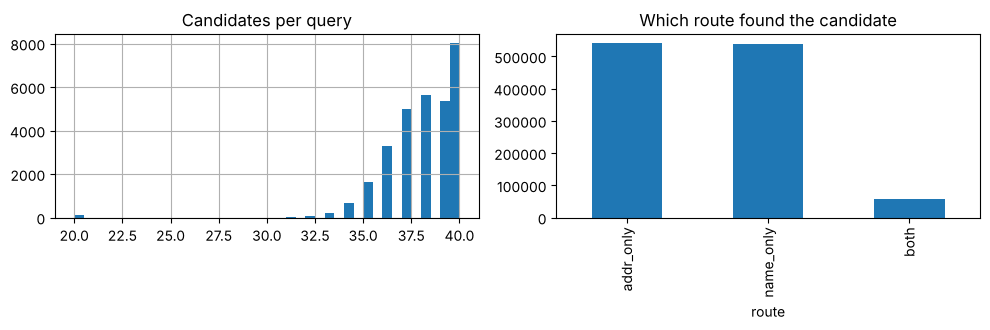

In [4]:
cand["route"] = np.where(cand["name_rank"].notna() & cand["addr_rank"].notna(), "both",
                 np.where(cand["name_rank"].notna(), "name_only", "addr_only"))
per_q = cand.groupby("s1_id").size().reindex(s1["s1_id"]).fillna(0)
print(f"candidates per query: mean {per_q.mean():.1f} | p5 {per_q.quantile(.05):.0f} | median {per_q.median():.0f} | p95 {per_q.quantile(.95):.0f} | max {per_q.max():.0f} | queries with 0: {(per_q==0).sum()}")
print("route share:", cand["route"].value_counts(normalize=True).round(3).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
per_q.hist(bins=40, ax=ax[0]); ax[0].set_title("Candidates per query");
cand["route"].value_counts().plot.bar(ax=ax[1]); ax[1].set_title("Which route found the candidate")
plt.tight_layout(); plt.show()

## 4. Real recall on the full pool, and the ceiling it puts on the score

Truth comes from the ground-truth file of each split. **Recall here is measured, not extrapolated.** Phase 3 predicted ≈ 96.1 % (train).

**Retrieval ceiling.** If a perfect classifier picked exactly the true matches inside the candidate list, each entity's precision would be 1 and its
recall `found/true`, so its F0.5 = 1.25·R / (0.25 + R) (singletons score 1.0). The mean over entities is the best score any classifier could reach with this retrieval.

In [5]:
def load_truth(path, ids):
    g = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False)
    g = g[g["source1_entity_id"].isin(ids)]
    g = g.assign(cand_id=g["matched_entity_ids"].str.split(",")).explode("cand_id")
    g = g[g["cand_id"] != ""].rename(columns={"source1_entity_id": "s1_id"})[["s1_id", "cand_id"]]
    return g

truth = {"train": load_truth(SPLIT_DIR + "/train_ground_truth.tsv", tr_s),
         "val": load_truth(SPLIT_DIR + "/val_ground_truth.tsv", va_s)}      # val: reporting only
cand["label"] = 0
rows = []
for sp_name, g in truth.items():
    key = set(zip(g["s1_id"], g["cand_id"]))
    m = cand["split"] == sp_name
    cand.loc[m, "label"] = [int((a, b) in key) for a, b in zip(cand.loc[m, "s1_id"], cand.loc[m, "cand_id"])]
    cset = set(zip(cand.loc[m, "s1_id"], cand.loc[m, "cand_id"]))
    g = g.copy(); g["found"] = [(a, b) in cset for a, b in zip(g["s1_id"], g["cand_id"])]
    truth[sp_name] = g
    ents = (s1[s1["split"] == sp_name]["s1_id"])
    pe = g.groupby("s1_id")["found"].agg(["sum", "size"]).reindex(ents).fillna(0)
    R = (pe["sum"] / pe["size"].replace(0, np.nan))
    F = np.where(pe["size"] == 0, 1.0, 1.25 * R.fillna(0) / (0.25 + R.fillna(0)))
    rows.append(dict(split=sp_name, true_pairs=len(g), pair_recall=g["found"].mean(),
                     entities_any_found=float((pe.loc[pe["size"] > 0, "sum"] > 0).mean()),
                     entities_all_found=float((pe.loc[pe["size"] > 0, "sum"] == pe.loc[pe["size"] > 0, "size"]).mean()),
                     ceiling_macro_F05=float(np.mean(F))))
rec = pd.DataFrame(rows).set_index("split"); display(rec.round(4))
print(f"Phase 3 extrapolation (train): 96.1% pair recall  ->  measured: {rec.loc['train','pair_recall']:.2%}")
print(f"val vs train recall gap: {rec.loc['val','pair_recall']-rec.loc['train','pair_recall']:+.4f}  (held-out sanity check only)")

,true_pairs,pair_recall,entities_any_found,entities_all_found,ceiling_macro_F05
split,,,,,
train,83493,0.9293,0.9911,0.8116,0.9733
val,20689,0.9289,0.9901,0.8133,0.9724


Phase 3 extrapolation (train): 96.1% pair recall  ->  measured: 92.93%
val vs train recall gap: -0.0004  (held-out sanity check only)


### 4b. Which route found the true pairs, and where does retrieval still miss?
Raw text of every candidate **and** every true match is fetched (one chunked scan of S2/S3) — also needed for Phase 5 features.

In [6]:
t0 = time.time()
need = set(cand["cand_id"]) | set(truth["train"]["cand_id"]) | set(truth["val"]["cand_id"])
raw = CG.fetch_raw(need, [S2P, S3P]).drop_duplicates("cand_id")
print(f"fetched raw text for {len(raw):,} records in {time.time()-t0:.0f}s")
NON_ASCII = re.compile(r"[^\x00-\x7F]")
qinfo = s1.set_index("s1_id")
tt = pd.concat([truth["train"].assign(split="train"), truth["val"].assign(split="val")]).merge(raw, on="cand_id", how="left")
tt["s1_name"] = tt["s1_id"].map(qinfo["s1_name"]); tt["s1_addr"] = tt["s1_id"].map(qinfo["s1_addr"]); tt["country"] = tt["s1_id"].map(qinfo["country"])
tt = tt.merge(cand[["s1_id", "cand_id", "route"]], on=["s1_id", "cand_id"], how="left")
tt["route"] = tt["route"].fillna("missed")
tt["nonascii"] = tt["c_name"].str.contains(NON_ASCII)
tt["addr_missing"] = (tt["c_addr"].str.strip() == "") | (tt["s1_addr"].str.strip() == "")
print("true pairs by route (train):"); print(tt[tt.split == "train"]["route"].value_counts(normalize=True).round(4).to_string())
sub = []
for col in ["country", "nonascii", "addr_missing"]:
    for v, g in tt[tt.split == "train"].groupby(col):
        sub.append(dict(group=f"{col}={v}", n=len(g), recall=float((g["route"] != "missed").mean())))
display(pd.DataFrame(sub).set_index("group").round(4))
ms = tt[(tt.split == "train") & (tt.route == "missed")]
print(f"missed train pairs: {len(ms):,}. Examples:")
display(ms.sample(min(10, len(ms)), random_state=1)[["s1_name", "c_name", "s1_addr", "c_addr"]])

fetched raw text for 870,376 records in 49s


true pairs by route (train):
route
both         0.4558
addr_only    0.3961
name_only    0.0773
missed       0.0707


,n,recall
group,,
country=India,33389,0.9035
country=US,50104,0.9465
nonascii=False,72051,0.9361
nonascii=True,11442,0.8863
addr_missing=False,79825,0.9431
addr_missing=True,3668,0.6295


missed train pairs: 5,905. Examples:


,s1_name,c_name,s1_addr,c_addr
38875,India India Limited,>> India Ilgrna Limited,"12, Amar Dham Row House Hanuman Chowk, Tadwadi...","828 12, Surat, GJ"
26820,Raj Consulting Private Limited,M/s Raj Consulting Private,"70B, Lenin Sarani, Kolkata, Kolkata, Howrah, W...","70B, Calcutta, Howrah, WB"
4768,Adityaraj Interiors Private Limited,Adityaraj Interiors Pbrtmate Limited,"Plot No. 2, Raidurg Nav, Khalsa, Gachibowli, S...","Plot No. 2, Bangalore, TG"
62233,Sloan Carlyle P.C.,Sloan P.C. Center,"4525 36th Avenue, Omaha, NE","4525 36st Ave, Omaha, Nebraska"
68638,Vision Associates LLC,Vision LLC [(Associates)],"36 Chickadee Lane, Hempstead, NY",
21700,Royal Technology Private Limited,रॉयल टेक्नोलॉजी प्राइवेट लिमिटेड,"G-8-A, No. 1, Bhagirath Palace, North East, De...","737, North East, Delhi, दिल्ली"
29662,A Elite Group,A Elite LLC,"11050 Bryant Street, Unit UNIT 213, Yucaipa, CA","Bryant St, Yucaipa, California"
24803,Hotel Infotech Limited,ಹೋಟೆಲ್ ಇನ್‌ಫೋಟೆಕ್ ಲಿಮಿಟೆಡ್,"No. 308, Iii Floor, Embassy Centre, 11, Cresce...","NO. 308, BANGALORE, Karnataka"
76450,Kolkata Sai Private Limited,privatekolkatasai.com,"30 Bentinck St, Kolkata, Howrah, West Bengal","KOLKATA, BENTINKC ST, পশ্চিমবঙ্গ, KOLKATA"
61954,Prairie Alliance,PRAIRIE ALLIANCE,"349 Orchard Road, Yorktown, NY","849 ORCHARD ROAD, NY, JEFFERSON VALLEY"


## 5. Candidate quality (what the classifier will face)
Class balance → class weights for Phase 8; and the highest-scoring **non-matches** (the genuinely hard negatives).

In [7]:
tr = cand[cand["split"] == "train"]
pos_rate = tr["label"].mean()
print(f"train candidates: {len(tr):,} | positives: {int(tr['label'].sum()):,} ({pos_rate:.2%}) | negative:positive = {(1-pos_rate)/pos_rate:.1f} : 1")
print("positive rate by route:", tr.groupby("route")["label"].mean().round(3).to_dict())
tr2 = tr.merge(raw, on="cand_id", how="left"); tr2["s1_name"] = tr2["s1_id"].map(qinfo["s1_name"]); tr2["s1_addr"] = tr2["s1_id"].map(qinfo["s1_addr"])
hard = tr2[(tr2["label"] == 0) & (tr2["route"] == "both")].sort_values("name_score", ascending=False).head(10)
print("\nhard negatives (found by both routes, label 0):")
display(hard[["s1_name", "c_name", "s1_addr", "c_addr", "name_score", "addr_score"]])

train candidates: 910,783 | positives: 77,588 (8.52%) | negative:positive = 10.7 : 1


positive rate by route: {'addr_only': 0.076, 'both': 0.804, 'name_only': 0.015}



hard negatives (found by both routes, label 0):


,s1_name,c_name,s1_addr,c_addr,name_score,addr_score
867853,Shearman Lifesciences Inc,SHEARMAN LIFESCIENCES PARTNERS [CO],"10616 Jacksonhole Place, White Plains, MD","WHITE PLAAINS, MD, ##10625 JACKSONHOLE PL",1.0,0.497417
746299,Crystal Genomic Networks Corp,CRYSTAL GENOMIC NETWORKS GROUP,"12 Willow Circle, Colchester, VT","16 WILLOW CIR, COLCHESTER, VT",1.0,0.710219
614580,Nenoon Investments L.L.C.,Nenoon Investments Co.,"4906 Chad Drive, Killeen, TX","4909 CHAD DR, KILLEEN, TX",1.0,0.639815
185976,Chatterjee Polytechnic Pvt Ltd,CHATTERJEE POLYTECHNIC VENTURES PVT LIMITED,"A-180, Iii Floor Meera Bagh, Delhi, West Delhi...","Delhi, A-187, III FLOOR MEERA BAGH, DELHI",1.0,0.706655
899273,Jeralee Richardson Patriot Citizens,Jeralee Richardson Patriot Citizens Ltd,"1009 Fourth Avenue, Dixon, IL","1011 Fourth Ave, Dixon, Illinois",1.0,0.581267
256981,Udaipur Renewables Pvt. Ltd.,UDAIPUR RENEWABLES OVERSEAS PVT. LTD,"140, Nag Marg Outside Chandpole, Udaipur, Raja...","149, NAG MARG OUTSIDE CHANDPOLE, UDAIPUR, Raja...",1.0,0.866119
577836,Fabiano Montessori School Inc,Fabiano Montessori School Partners Ltd,"NY, Rochester, 90 Delmar Street","92 DELMAR ST, NY, ROCHESTER",1.0,0.704390
792001,Kaitlin Patterson Midwest Labs LLC,Kaitlin Patterson Midwest Labs Corp,"297 Front Street, Cygnet, OH","300. Front St, Cygnet, Ohio",1.0,0.701476
47501,Goldensight Builders Limited,Goldensight Builders Industries Limited,"Shop No. 02, Reengus Road Naer Petrol Pump, Kh...","NO D/9 , REENGUS ROAD NAER PETROL PUMP, KHATUS...",1.0,0.840304
479509,General Equity Concepts,[Inc] General Equity Concepts,"Saint Louis, MO, Fl 0, 8333 Fullerton Avenue","008338 Fullerton Ave, Floor 0, Saint Louis, Mi...",1.0,0.571856


## 6. Save the labelled candidate tables
`candidates_train.pkl` / `candidates_val.pkl`: raw S1 + candidate text, retrieval ranks/scores, route and label.
The label column in the val table is for **evaluation only** (Phase 9); nothing is fit on it.

In [8]:
full = cand.merge(raw, on="cand_id", how="left")
full["s1_name"] = full["s1_id"].map(qinfo["s1_name"]); full["s1_addr"] = full["s1_id"].map(qinfo["s1_addr"])
cols = ["s1_id", "s1_name", "s1_addr", "country", "cand_id", "c_name", "c_addr", "name_rank", "name_score", "addr_rank", "addr_score", "route", "label", "split"]
for name in ["train", "val"]:
    d = full[full["split"] == name][cols].reset_index(drop=True)
    d.to_pickle(f"{INTERIM}/candidates_{name}.pkl")
    print(f"saved candidates_{name}.pkl: {len(d):,} rows, {d['s1_id'].nunique():,} queries")
truth_out = {k: v for k, v in truth.items()}
pickle.dump(dict(truth=truth_out, queries=s1), open(INTERIM + "/phase4_truth_and_queries.pkl", "wb"))

saved candidates_train.pkl: 910,783 rows, 24,000 queries


saved candidates_val.pkl: 227,888 rows, 6,000 queries


## 7. Summary and hand-off

In [9]:
print("=== PHASE 4 SUMMARY ===")
print(f"Queries: {N_TRAIN_Q:,} train + {N_VAL_Q:,} val | ~{per_q.mean():.0f} candidates/query | {len(cand):,} pairs")
print(f"Measured pair recall (full pool): train {rec.loc['train','pair_recall']:.2%} | val {rec.loc['val','pair_recall']:.2%}  (Phase 3 predicted ~96.1%)")
print(f"Retrieval ceiling on macro F0.5: train {rec.loc['train','ceiling_macro_F05']:.4f} | val {rec.loc['val','ceiling_macro_F05']:.4f}")
print(f"Class balance (train): {pos_rate:.2%} positive -> use class weights in Phase 8")
print("Hand-off to Phase 5: candidates_train.pkl / candidates_val.pkl in dataset/interim/.")
print("No retrieval setting was changed and no validation label influenced any decision.")

=== PHASE 4 SUMMARY ===
Queries: 24,000 train + 6,000 val | ~38 candidates/query | 1,138,671 pairs
Measured pair recall (full pool): train 92.93% | val 92.89%  (Phase 3 predicted ~96.1%)
Retrieval ceiling on macro F0.5: train 0.9733 | val 0.9724
Class balance (train): 8.52% positive -> use class weights in Phase 8
Hand-off to Phase 5: candidates_train.pkl / candidates_val.pkl in dataset/interim/.
No retrieval setting was changed and no validation label influenced any decision.
